# Photometric normalisation (eye / tag)

Uses the in-frame references of each head image: the brightest 20 % of the ID-tag pixels (white) and the darkest 20 % of the eye pixels (black), from `labels/tags_eyes`. Each operculum ROI is mapped so that eye = 0 and tag = 1, and saved to `images/normalized_operculums/`; the un-normalised grayscale ROI goes to `images/grayscale_operculum/`. Set `GROUP` to choose the fish group.

In [6]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

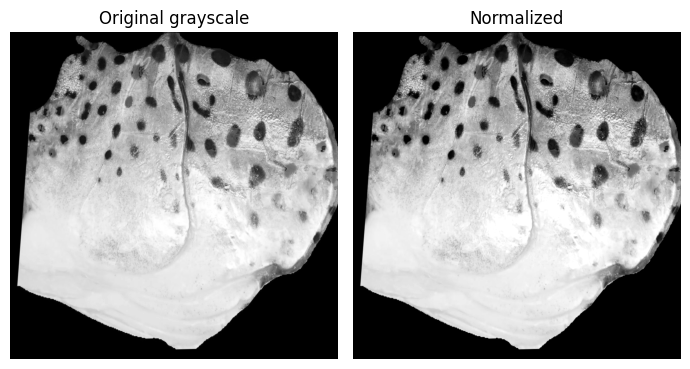

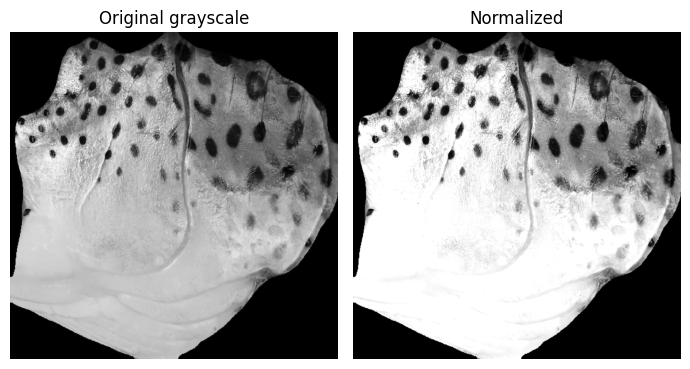

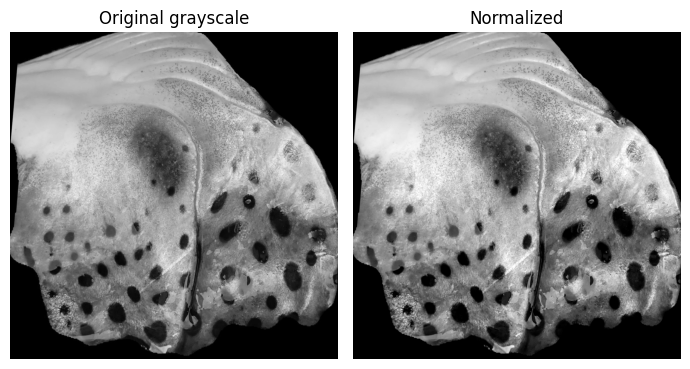

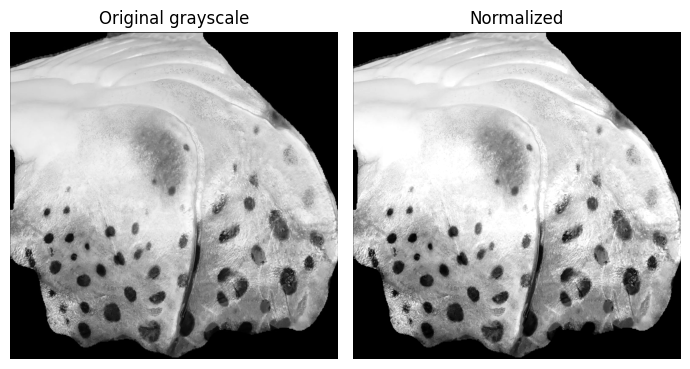

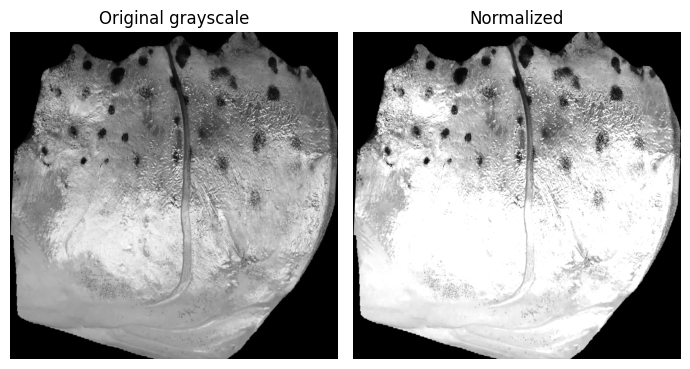

...

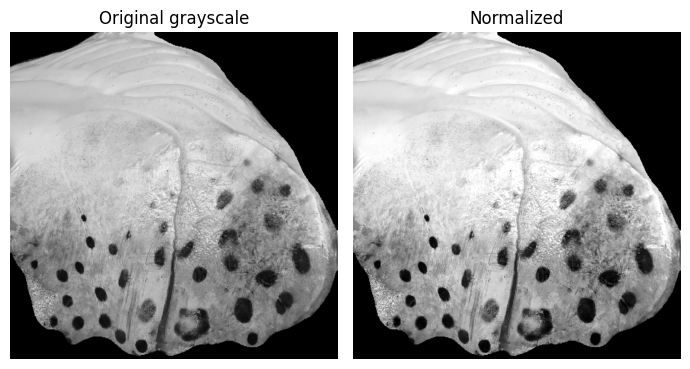

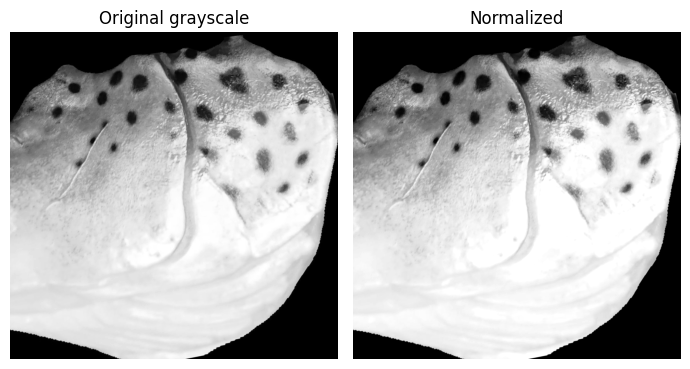

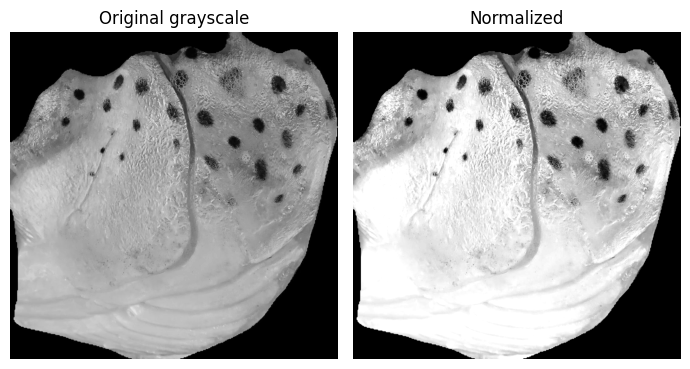

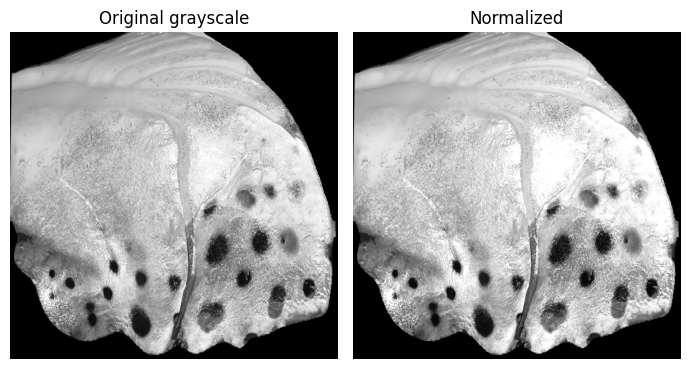

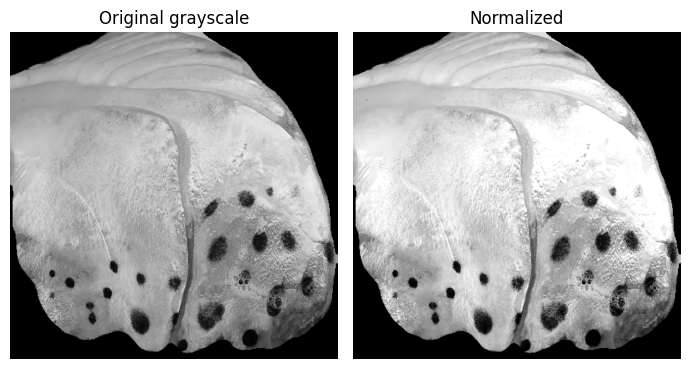

In [7]:
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "fish_ids.csv").is_file())
GROUP = "stressed"
DATA = ROOT / "data" / GROUP

image_dir = DATA / "images" / "head_images"
labels_dir = DATA / "labels" / "tags_eyes"
roi_dir = DATA / "images" / "operculum_images"

stand_dir = DATA / "images" / "normalized_operculums"
gray_scale_dir = DATA / "images" / "grayscale_operculum"

os.makedirs(stand_dir, exist_ok=True)
os.makedirs(gray_scale_dir, exist_ok=True)


def load_paths(directory):
    """
    Load all file paths from a directory into a dictionary.

    Dictionary format:
        {
            filename_without_extension: full_file_path
        }
    """
    paths = {}

    for file_name in sorted(os.listdir(directory)):
        key = os.path.splitext(file_name)[0]
        paths[key] = os.path.join(directory, file_name)

    return paths


img_paths = load_paths(image_dir)
roi_paths = load_paths(roi_dir)
lbl_paths = load_paths(labels_dir)


def load_bbox_details(label_paths):
    """
    Load oriented bounding box details from label files.

    Each label file is expected to contain rows in the format:
        class_id x1 y1 x2 y2 x3 y3 x4 y4

    Coordinates are assumed to be normalized between 0 and 1.
    """
    labels = {}

    for key, path in label_paths.items():
        with open(path, "r") as file:
            content = file.readlines()

        labels[key] = [line.split() for line in content]

    return labels


lbls_det = load_bbox_details(lbl_paths)


def sorting_custom(file_key):
    """
    Sort files based on fish ID and side.

    Expected filename structure includes:
        something_<fish_id>_..._<side>_something

    Example:
        fish_12_xyz_left_img
    """
    try:
        parts = file_key.split("_")

        fish_id = int(parts[1])
        side = parts[-2]

        return fish_id, side

    except Exception as error:
        print(f"Could not sort file key: {file_key}. Error: {error}")
        return float("inf"), ""


sorted_fish_paths = dict(
    sorted(img_paths.items(), key=lambda x: sorting_custom(x[0]))
)

sorted_fish_roi_paths = dict(
    sorted(roi_paths.items(), key=lambda x: sorting_custom(x[0]))
)

fnames = list(sorted_fish_paths.keys())


def get_mask_enclosed_areas(fnames, image_paths, labels):
    """
    Extract pixel intensities from eye and tag regions.

    For each fish image:
    - Load the image in grayscale
    - Resize to 1080 x 1080
    - Read polygon annotations
    - Create a binary mask from each polygon
    - Extract pixels inside the mask

    Returns:
        Dictionary containing pixel intensities for each region.
    """
    mask_enclosed_areas = {}

    for fn in fnames:
        img = Image.open(image_paths[fn]).convert("L")
        img = img.resize((1080, 1080), Image.Resampling.BICUBIC)

        img_arr = np.array(img, dtype=np.uint8)
        img_width, img_height = img.size

        for bbox in labels[fn]:
            values = [float(x) for x in bbox]

            class_id = int(values[0])
            vertices = values[1:]

            pixel_vertices = [
                int(vertices[j] * img_width) if j % 2 == 0
                else int(vertices[j] * img_height)
                for j in range(len(vertices))
            ]

            mask = Image.new("L", img.size, 0)
            ImageDraw.Draw(mask).polygon(
                pixel_vertices,
                outline=1,
                fill=1
            )

            mask_np = np.array(mask, dtype=np.uint8)

            seg_pixels = img_arr[mask_np == 1]

            region_name = "eye" if class_id == 0 else "tag"

            mask_enclosed_areas[f"{fn}_{region_name}"] = seg_pixels

    return mask_enclosed_areas


mask_enclosed_areas = get_mask_enclosed_areas(
    fnames=fnames,
    image_paths=img_paths,
    labels=lbls_det
)


tag_vals = []
eye_vals = []

percent_threshold = 0.20

for fn in sorted_fish_paths.keys():
    tag_key, eye_key = f"{fn}_tag", f"{fn}_eye"
    if tag_key not in mask_enclosed_areas or eye_key not in mask_enclosed_areas:
        raise KeyError(f"{fn}: label file must contain both an eye (class 0) and a tag")

    pixel_intense_tags = np.sort(mask_enclosed_areas[tag_key])[::-1]
    pixel_intense_eyes = np.sort(mask_enclosed_areas[eye_key])

    index_tag = max(1, int(percent_threshold * pixel_intense_tags.shape[0]))
    index_eye = max(1, int(percent_threshold * pixel_intense_eyes.shape[0]))

    tag_intensity_mean = pixel_intense_tags[:index_tag].mean()
    eye_intensity_mean = pixel_intense_eyes[:index_eye].mean()

    tag_vals.append(tag_intensity_mean)
    eye_vals.append(eye_intensity_mean)


df_stand = pd.DataFrame({
    "FISH": list(sorted_fish_paths.keys()),
    "tags": tag_vals,
    "eyes": eye_vals
})

bad = df_stand[df_stand["tags"] <= df_stand["eyes"]]
if not bad.empty:
    print("WARNING: tag not brighter than eye for:\n", bad.to_string())


fnames = list(sorted_fish_roi_paths.keys())

for fn in fnames:
    fig, ax = plt.subplots(1, 2, figsize=(7, 7))

    img = Image.open(roi_paths[fn]).convert("L")
    img = img.resize((1080, 1080), Image.Resampling.BICUBIC)

    img_arr = np.array(img, dtype=np.float64) / 255.0

    alpha = df_stand.loc[df_stand["FISH"] == fn, "tags"].values[0]
    beta = df_stand.loc[df_stand["FISH"] == fn, "eyes"].values[0]

    alpha = alpha / 255.0
    beta = beta / 255.0

    img_normalized = (img_arr - beta)/(alpha - beta + 1e-8)
    img_normalized = np.clip(img_normalized, 0, 1)

    img_normalized_pil = Image.fromarray(
        np.array(img_normalized * 255, dtype=np.uint8)
    )

    img_normalized_pil.save(
        os.path.join(stand_dir, f"{fn}.jpg"),
        subsampling=0,
        quality=100,
        format="jpeg"
    )

    img_gray_pil = Image.fromarray(
        np.array(img_arr * 255, dtype=np.uint8)
    )

    img_gray_pil.save(
        os.path.join(gray_scale_dir, f"{fn}.jpg"),
        subsampling=0,
        quality=100,
        format="jpeg"
    )

    ax[0].imshow(img_arr, cmap="gray")
    ax[0].set_title("Original grayscale")
    ax[0].axis("off")

    ax[1].imshow(img_normalized, cmap="gray")
    ax[1].set_title("Normalized")
    ax[1].axis("off")

    plt.tight_layout()
    plt.show()